In [13]:
from matplotlib import pyplot as plt
import cv2
import numpy as np

(266, 458)


(<AxesSubplot:>, <matplotlib.image.AxesImage at 0x7f9e5ce0cdf0>)

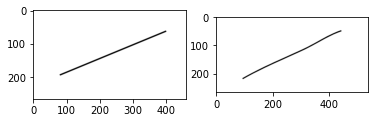

In [8]:
straight_line = cv2.imread("straight_line.png", cv2.IMREAD_GRAYSCALE)
curvy_line = cv2.imread("curvy_line.png", cv2.IMREAD_GRAYSCALE)
plt.subplot(121), plt.imshow(straight_line, cmap='gray')
plt.subplot(122), plt.imshow(curvy_line, cmap='gray')

In [15]:
grad_x_sl = cv2.Sobel(straight_line, cv2.CV_32F, 1, 0, ksize=3)
grad_y_sl = cv2.Sobel(straight_line, cv2.CV_32F, 0, 1, ksize=3)

grad_x_cl = cv2.Sobel(curvy_line, cv2.CV_32F, 1, 0, ksize=3)
grad_y_cl = cv2.Sobel(curvy_line, cv2.CV_32F, 0, 1, ksize=3)

orient_sl = cv2.phase(grad_x_sl, grad_y_sl, angleInDegrees=True)
orient_cl = cv2.phase(grad_x_cl, grad_y_cl, angleInDegrees=True)

orient_sl = orient_sl.flatten()
orient_cl = orient_cl.flatten()

orient_sl = orient_sl[orient_sl > 0]
orient_cl = orient_cl[orient_cl > 0]

hist_sl = np.array([0 for i in range(36)])
hist_cl = np.array([0 for i in range(36)])

for orient in orient_sl:
    which_bin = int(orient // 10)
    hist_sl[which_bin] += 1
print(hist_sl)
    
for orient in orient_cl:
    which_bin = int(orient // 10)
    hist_cl[which_bin] += 1
print(hist_cl)

[  1   1   1   0 153 327 852 107   0  11   1   1   1   6   1   7   0   0
   9   8   9  40 180 394 890  80   0   2   1   0   3   4   2   6   1   0]
[  0   1   1   0 262 374 948  43   0  10  13   1   0   9   1   4   9   0
   4   7   5  52 257 515 957  28   0   3   1   0   2   6   1   2   4   3]
